# Model Testing — Rylyn's Model (Event Edition)

This notebook checks Rylyn's model. It **runs `rylyn_model.ipynb` first** (so it always tests exactly the current code and settings), then:

| Section | Question it answers |
|---|---|
| A. Data checks | Are the files fresh? Are Rylyn's two open high-severity data flags still there? |
| B. Model sanity checks | Probabilities 0–100%, seat counts possible, the two simulations agree, mean seats match the race probabilities |
| C. Correlation check | Do the factor draws reproduce the starter's correlation matrix? (Rylyn's own check) |
| D. Reproduces Rylyn's published run | As of Oct 15 with 40,000 simulations, the script gave 66.6%. Does this port? |
| E. Sensitivity sweep | Rylyn's sweep: every setting at its low and high value |
| F. Random seeds | Is the answer stable across seeds? |
| G. Summary | Every check, saved to `Output/testing/checks.csv` (read by `run_all.py`) |

**Reading the checks:** **PASS** (fine), **WARN** (worth a look), **FAIL** (something is broken; don't publish this run).


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


run_all.py overrides: AS_OF_DATE = 2026-10-29, N_SIMS = 10,000
State polls:


  pollster name: 'Cygnal Politial' -> 'Cygnal Political'
  pollster name: 'Fabrizio, Lee, & Asspcoates' -> 'Fabrizio, Lee & Associates'
  pollster name: 'St. Pete Pols' -> 'St. Pete Polls'
  pollster name: 'St.Pete Polls' -> 'St. Pete Polls'
National polls:
  pollster name: 'HarrixX/Harris Poll' -> 'HarrisX/Harris Poll'
  pollster name: 'Morning consult' -> 'Morning Consult'
51 states with leans, 232 state polls, 37 national polls
4 active opinion events, 11 access scenarios (5 active), 1 map events
Weighted presidential net approval: -22.9  ->  national environment D+8.0


Forecast as of 2026-10-29 with 10,000 simulations (1 s)

No events (starter model)      D seats median 52, 80% interval 49-55, P(D control) 67.0%
Main forecast (with events)    D seats median 52, 80% interval 49-55, P(D control) 67.0%
Model date 2026-10-29, 5 days to the election, 10,000 simulations. National environment D+8.0.

Opinion events (prior combined with same-pollster estimates)
------------------------------------------------------------
          prior_mean  prior_sd  pairs  poll_estimate  poll_se  post_mean  post_sd  weight_on_polls
event_id                                                                                          
OP1              0.5      1.00      4          -0.54     0.72      -0.19     0.59             0.66
OP2              0.5      0.75      2           0.74     3.76       0.51     0.74             0.04
OP3              0.0      0.75      0            NaN      NaN       0.00     0.75             0.00
OP4              0.0      1.00      3          -0.51

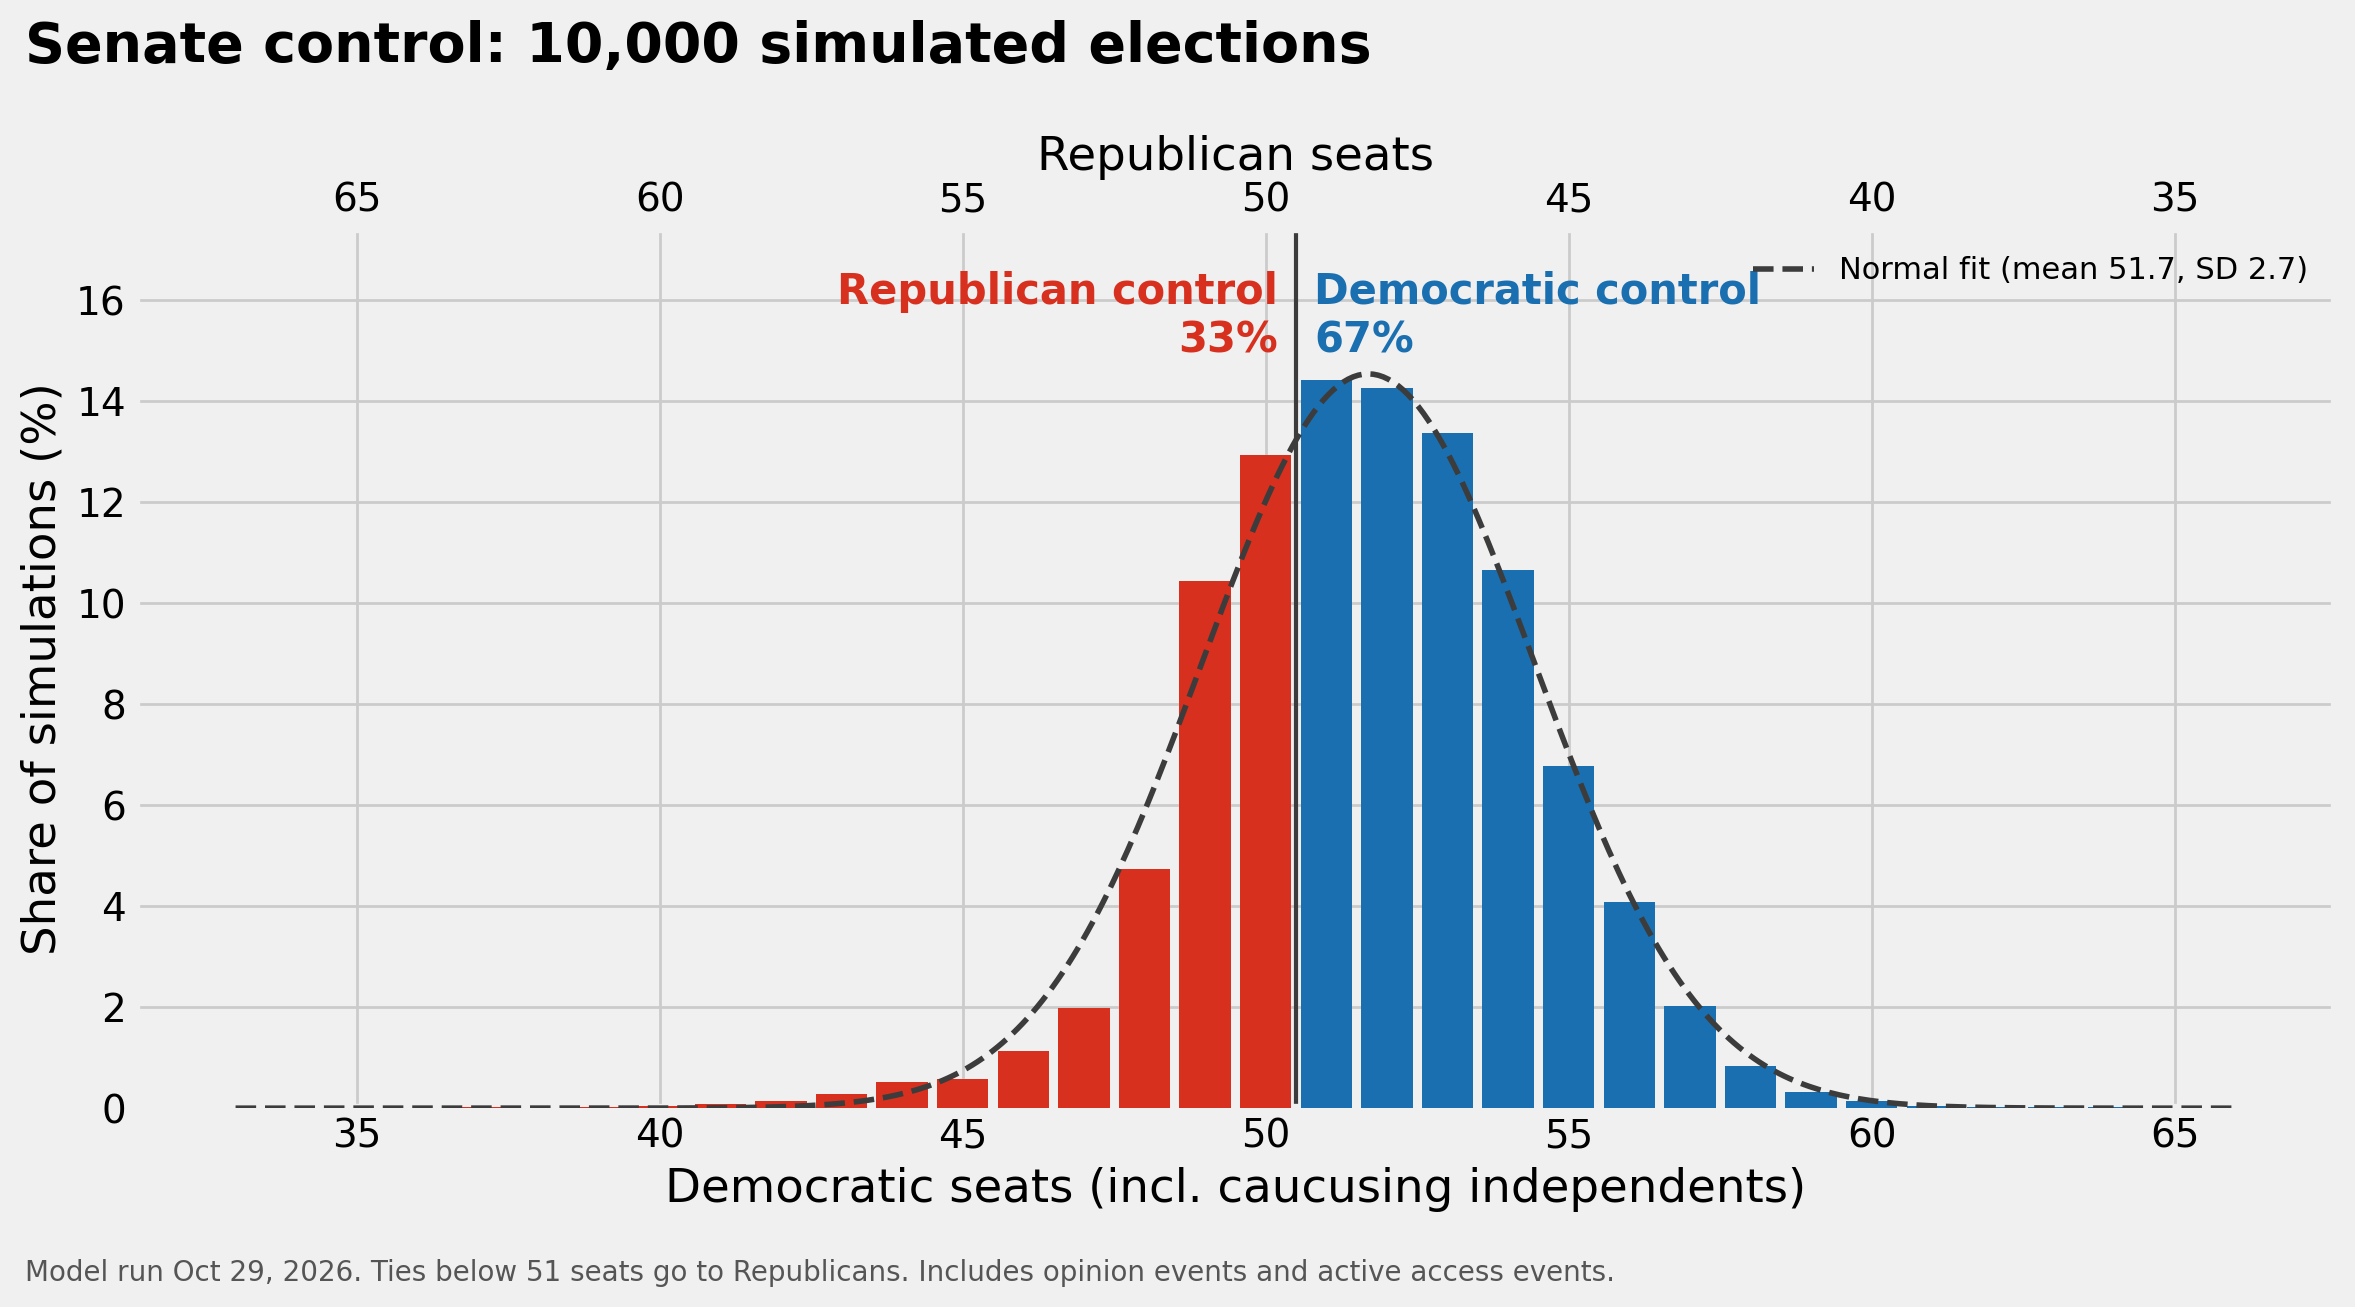


Scenarios (access rows marked active are in the main forecast)
--------------------------------------------------------------
                                P(D control)  Mean D seats  D seats, 10th pct  D seats, 90th pct  Change vs opinion only (pts)
No events (starter model)              67.0%         51.69               49.0               55.0                         -0.13
Opinion events only                    67.1%         51.69               49.0               55.0                          0.00
Main forecast                          67.0%         51.69               49.0               55.0                         -0.08
Opinion + OH-GRACE                     67.0%         51.69               49.0               55.0                         -0.07
Opinion + TX-TARRANT                   67.1%         51.69               49.0               55.0                          0.00
Opinion + KS-GRACE                     67.1%         51.69               49.0               55.0               


Competitive races: ballots that would have to be lost (lost voters favor the leader by 20)
------------------------------------------------------------------------------------------
                median margin  P(D) share of electorate lost to erase margin
Alaska                   0.47  0.55                                     2.3%
Iowa                    -0.52  0.45                                     2.5%
Texas                    0.88  0.59                                     4.2%
Ohio                     1.80  0.68                                     8.3%
Kansas                  -1.89  0.31                                     8.7%
South Carolina          -4.06  0.17                                    16.9%
Florida                 -4.40  0.13                                    18.0%
Michigan                 4.56  0.88                                    18.6%
Nebraska                -5.03  0.12                                    20.1%


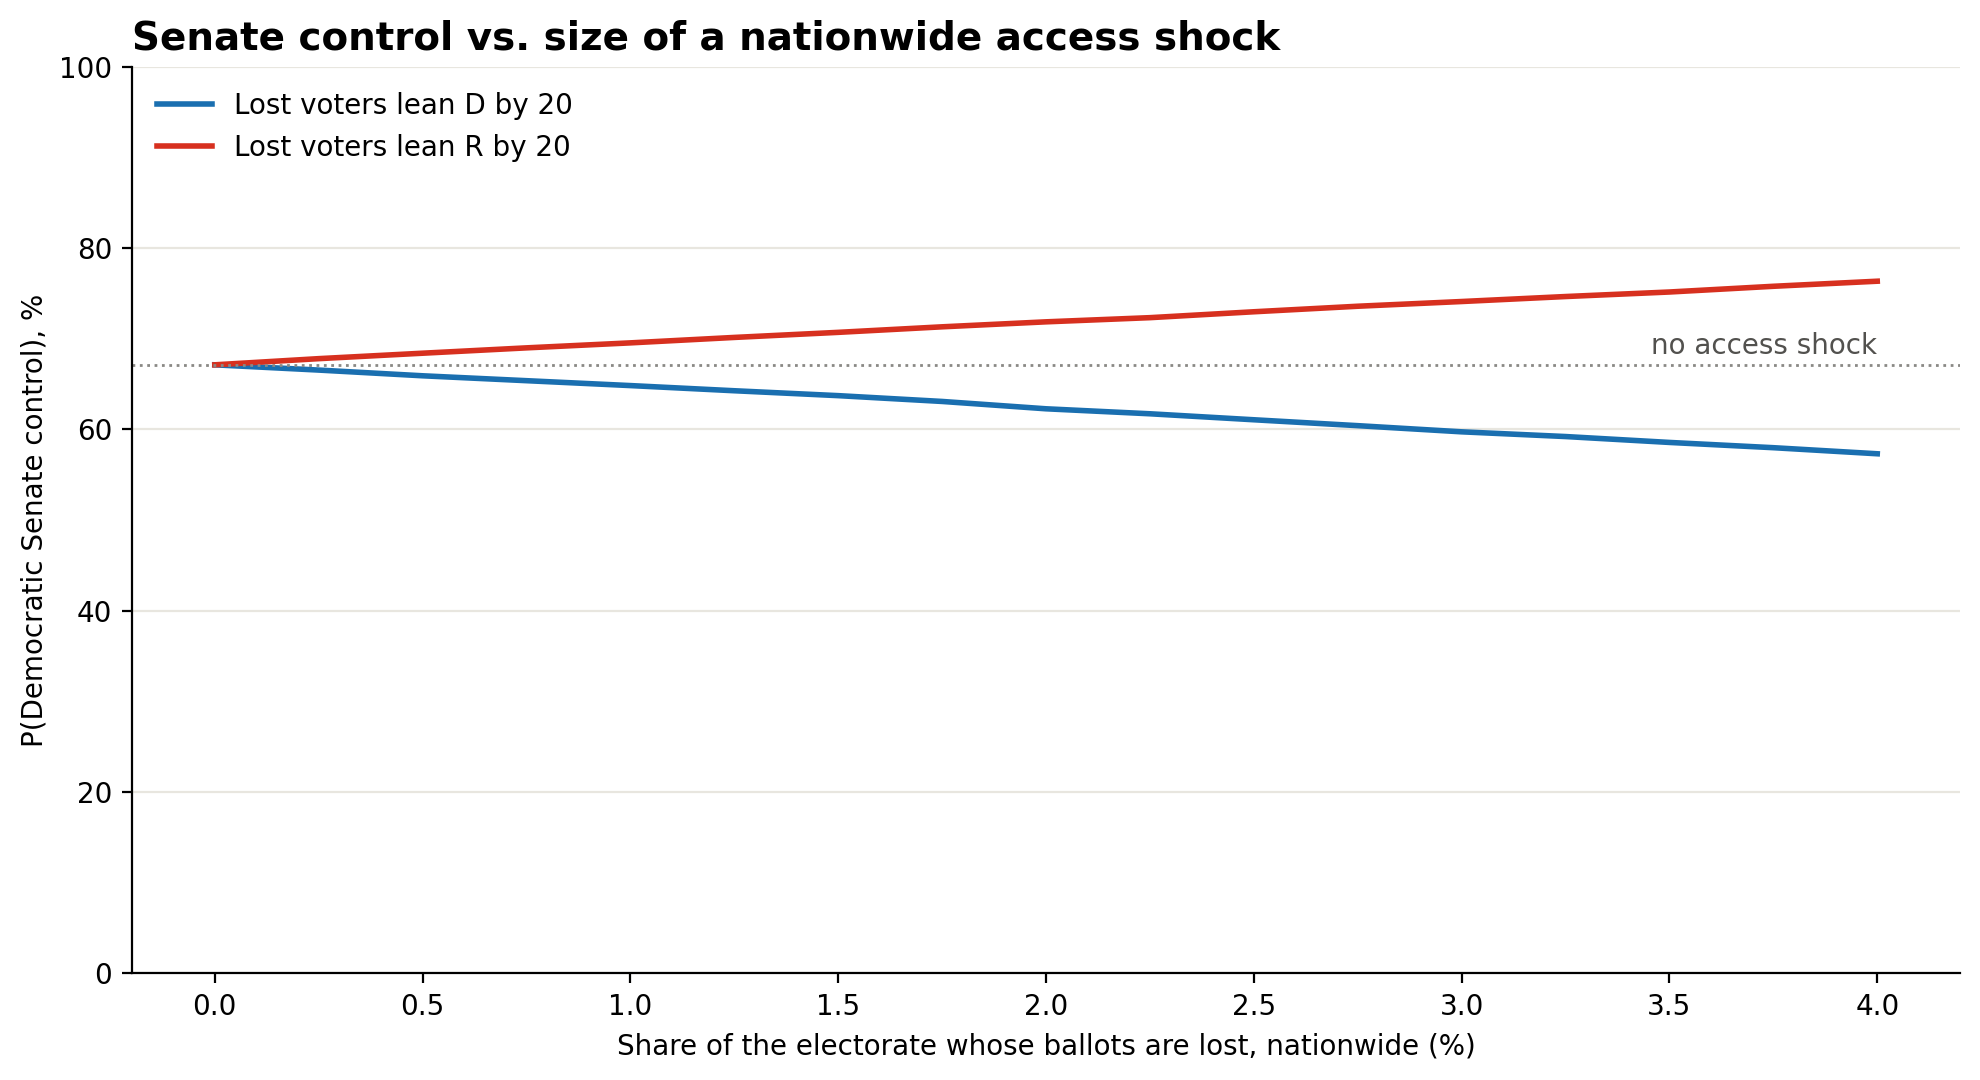


Map events change Senate margins by 0.0 points in every race (statewide races don't use district lines).



HYPOTHETICAL mid-decade redraw (TOY DATA) (Example State, 12 districts); statewide lean old -3.0, new -3.0
              old plan  new plan  new - old
mean D seats      6.41      2.91       -3.5
10th pct          5.00      2.00       -3.0
90th pct          8.00      5.00       -3.0
  P(new plan gives D fewer seats than old plan) = 99%


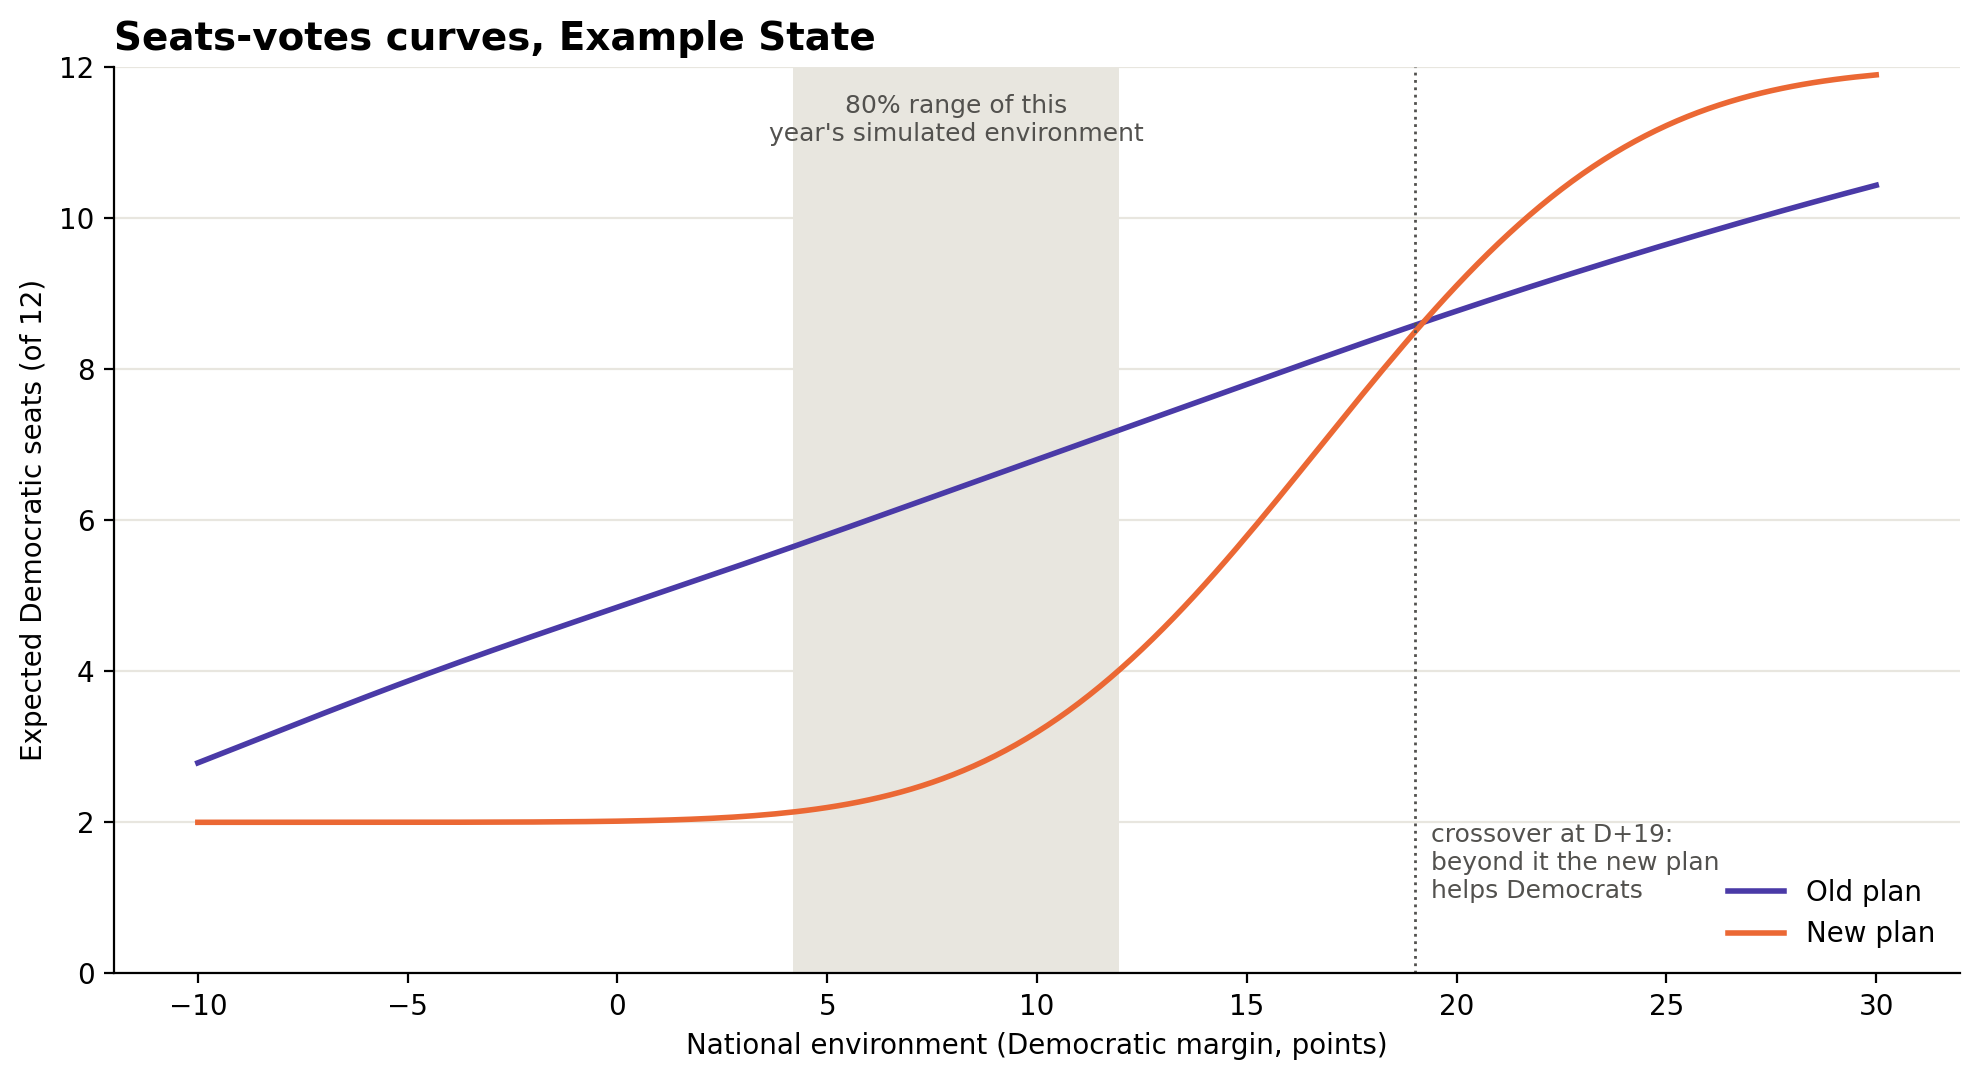


Win probabilities and ratings
-----------------------------
               Incumbent party Projected margin P(Dem win) P(Rep win)    Rating
State                                                                          
Massachusetts                D           D+29.9       100%         0%    Safe D
Rhode Island                 D           D+28.1       100%         0%    Safe D
Oregon                       D           D+24.1       100%         0%    Safe D
Delaware                     D           D+24.1       100%         0%    Safe D
Illinois                     D           D+17.3       100%         0%    Safe D
Colorado                     D           D+20.2        99%         1%    Safe D
New Jersey                   D           D+16.0        98%         2%    Safe D
North Carolina               R            D+9.0        98%         2%    Safe D
New Mexico                   D           D+11.1        98%         2%    Safe D
New Hampshire                D            D+8.8        98% 

In [1]:
%run ./rylyn_model.ipynb

In [2]:
TEST_DIR = OUT_DIR / "testing"
TEST_DIR.mkdir(parents=True, exist_ok=True)
CHECKS = []
COLORS = {"PASS": "background-color:#DFF0D8", "WARN": "background-color:#FCF8E3", "FAIL": "background-color:#F2DEDE"}


def check(section, name, status, detail):
    CHECKS.append({"section": section, "check": name, "status": status, "detail": detail})


def show_checks(section):
    t = pd.DataFrame([x for x in CHECKS if x["section"] == section])
    if not len(t):
        return
    try:
        display(t.drop(columns="section").style.map(lambda v: COLORS.get(v, ""), subset=["status"]))
    except (AttributeError, ImportError):
        display(t.drop(columns="section"))


races, sim = r.races, r.sim

## A. Data checks
- **Freshness:** Rylyn's files are the professor's **October 15** release, and nothing updates them automatically. A WARN here means the forecast date is well past the newest poll.
- **Polls after the forecast date:** the script doesn't drop polls dated after `--today` (it was always run on the release date). A backtest earlier than Oct 15 would see later polls.
- **Open flags from Rylyn's data check** (`notes/Data_check_2026-10-15.xlsx`): New Mexico SurveyUSA Oct 5 (54 + 47 > 100) and a duplicated AlphaROC approval poll.

In [3]:
newest = d.polls_raw["Date"].max()
age = (c.TODAY - newest).days
check("A", "newest state poll", "PASS" if age <= 7 else "WARN", f"{newest:%Y-%m-%d} ({age} days before the forecast date)")
nn = d.nat["Date"].max()
check("A", "newest approval poll", "PASS" if (c.TODAY - nn).days <= 14 else "WARN", f"{nn:%Y-%m-%d}")
future = (d.polls_raw["Date"] > c.TODAY).sum()
check("A", "polls dated after the forecast date", "PASS" if future == 0 else "WARN",
      f"{future} state polls are newer than {c.TODAY:%Y-%m-%d} and still count (the script has no as-of filter)")
over = d.polls_raw[(d.polls_raw["Dem%"] + d.polls_raw["Rep%"]) > 100]
check("A", "state polls with Dem% + Rep% > 100", "PASS" if over.empty else "WARN",
      "none" if over.empty else "; ".join(f"{x.State} {x.Pollster} {x.Date:%m/%d} ({x['Dem%']:g}+{x['Rep%']:g})" for _, x in over.iterrows()))
dup = d.nat[d.nat.duplicated(["Date", "Pollster", "Approval", "Disapproval", "SampleSize"], keep=False)]
check("A", "duplicate approval polls", "PASS" if dup.empty else "WARN",
      "none" if dup.empty else f"{len(dup)} rows: {sorted(set(dup['Pollster']))} (counted twice in the approval average)")
zero = (d.nat["SampleSize"].fillna(0) <= 0).sum()
check("A", "approval polls with no sample size", "PASS" if zero == 0 else "WARN", f"{zero} (get zero weight)")
missing = set(SEATS_UP) - set(d.leans.index)
check("A", "every race has a partisan lean", "PASS" if not missing else "FAIL", "all 35" if not missing else str(missing))
unr = d.polls_raw["Pollster Rank"].isna().sum()
check("A", "pollsters without a rank", "PASS", f"{unr} polls use UNRANKED_SCORE = {c.UNRANKED_SCORE}")
check("A", "events loaded", "PASS", f"{len(d.opinion)} opinion events, {int(d.access['active'].sum())} of {len(d.access)} access rows active, {len(d.maps)} map events")
show_checks("A")

,check,status,detail
0,newest state poll,WARN,2026-10-15 (14 days before the forecast date)
1,newest approval poll,PASS,2026-10-15
2,polls dated after the forecast date,PASS,0 state polls are newer than 2026-10-29 and still count (the script has no as-of filter)
3,state polls with Dem% + Rep% > 100,WARN,New Mexico SurveyUSA 10/05 (54+47)
4,duplicate approval polls,WARN,2 rows: ['AlphaROC'] (counted twice in the approval average)
5,approval polls with no sample size,WARN,1 (get zero weight)
6,every race has a partisan lean,PASS,all 35
7,pollsters without a rank,PASS,0 polls use UNRANKED_SCORE = 6.5
8,events loaded,PASS,"4 opinion events, 5 of 11 access rows active, 1 map events"


## B. Model sanity checks
Internal consistency: these should always PASS.

In [4]:
p_ok = races["p_dem_national_sim"].between(0, 1).all() and races["p_dem_state_sim"].between(0, 1).all()
check("B", "probabilities between 0 and 1", "PASS" if p_ok else "FAIL", "state and national simulations")
ds = sim["d_seats"]
check("B", "seat counts possible", "PASS" if ds.min() >= HOLDOVER_D and ds.max() <= HOLDOVER_D + 35 else "FAIL",
      f"range {ds.min()}-{ds.max()} (possible {HOLDOVER_D}-{HOLDOVER_D + 35})")
exp_from_races = HOLDOVER_D + sum(p * c.INDEPENDENT_CAUCUS_PROB_D.get(st, 1.0) for st, p in races["p_dem_national_sim"].items())
gap = abs(exp_from_races - ds.mean())
check("B", "mean seats = sum of race probabilities", "PASS" if gap < 0.15 else "WARN", f"{ds.mean():.2f} vs {exp_from_races:.2f}")
sim_gap = (races["p_dem_state_sim"] - races["p_dem_national_sim"]).abs().max()
check("B", "independent vs correlated simulations agree", "PASS" if sim_gap < 0.05 else "WARN",
      f"largest race gap {sim_gap:.1%} (access events enter only the correlated run)")
check("B", "no missing race margins", "PASS" if races["post_mean"].notna().all() and races["post_sd"].gt(0).all() else "FAIL", "post_mean / post_sd")
p = (ds >= c.D_SEATS_FOR_CONTROL).mean()
se = np.sqrt(p * (1 - p) / c.N_SIMS)
check("B", "simulation noise on P(control)", "PASS" if se < 0.01 else "WARN", f"±{1.96 * se:.1%} (95%) with {c.N_SIMS:,} simulations")
base_p = (r.sim_base["d_seats"] >= c.D_SEATS_FOR_CONTROL).mean()
check("B", "events vs no events", "PASS" if abs(p - base_p) < 0.05 else "WARN", f"{p:.1%} with events vs {base_p:.1%} without")
show_checks("B")

,check,status,detail
0,probabilities between 0 and 1,PASS,state and national simulations
1,seat counts possible,PASS,range 35-64 (possible 34-69)
2,mean seats = sum of race probabilities,PASS,51.69 vs 51.69
3,independent vs correlated simulations agree,PASS,largest race gap 1.3% (access events enter only the correlated run)
4,no missing race margins,PASS,post_mean / post_sd
5,simulation noise on P(control),PASS,"±0.9% (95%) with 10,000 simulations"
6,events vs no events,PASS,67.0% with events vs 67.0% without


## C. Correlation check
Rylyn's own check: the factor-built draws should reproduce the starter's correlation matrix.

In [5]:
R_target = correlation_matrix(races, c)
R_draws = np.corrcoef(r.draws["z"], rowvar=False)
gaps = np.abs(R_target - R_draws)[np.triu_indices(len(races), 1)]
check("C", "simulated vs target correlation", "PASS" if gaps.max() < 0.05 else "WARN",
      f"mean gap {gaps.mean():.3f}, largest {gaps.max():.3f}")
show_checks("C")

,check,status,detail
0,simulated vs target correlation,PASS,"mean gap 0.010, largest 0.035"


## D. Reproduces Rylyn's published run
Rylyn's README: *"The script gives 66.6% with `--today 2026-10-15` and the default `SEED` of 2026."* This re-runs the port with exactly those settings (40,000 simulations). A match confirms the port is faithful.

In [6]:
c_pub = make_context({**SETTINGS, "N_SIMS": 40_000}, "2026-10-15", verbose=False)
r_pub = forecast(d, c_pub, 40_000, with_base=False)
p_pub = (r_pub.sim["d_seats"] >= c_pub.D_SEATS_FOR_CONTROL).mean()
med_pub = np.median(r_pub.sim["d_seats"])
print(f"Port, Oct 15, 40,000 simulations: P(D control) {p_pub:.1%}, median {med_pub:.0f} seats (Rylyn's script: 66.6%, median 52)")
check("D", "reproduces Rylyn's 66.6% (Oct 15)", "PASS" if abs(p_pub - 0.666) < 0.006 else "FAIL",
      f"{p_pub:.1%}, median {med_pub:.0f}")
show_checks("D")

Port, Oct 15, 40,000 simulations: P(D control) 66.6%, median 52 seats (Rylyn's script: 66.6%, median 52)


,check,status,detail
0,reproduces Rylyn's 66.6% (Oct 15),PASS,"66.6%, median 52"


## E. Sensitivity sweep (Rylyn's)
Each setting at a **low** and a **high** value (Rylyn's `SWEEP` table, copied verbatim), everything else fixed. Same random draws for every run, so differences come from the setting. "Raising it helps" = which party gains when the setting goes from low to high (under half a point = neither). Runs with the current `N_SIMS`; saved to `Output/testing/sensitivity.csv`.

Baseline: P(D control) 67.0%, mean D seats 51.69


  ENV_SLOPE                     0.2 -> 0.5     P(D control) 52.5% -> 79.4%  (+26.9 pts)   most-moved race: Alaska +25


  PRIOR_SD                      5.0 -> 10.0    P(D control) 56.5% -> 71.1%  (+14.6 pts)   most-moved race: Kansas +29


  SYSTEMATIC_POLL_ERROR_SD      3.0 -> 6.0     P(D control) 77.0% -> 60.4%  (-16.6 pts)   most-moved race: Texas -23


  RV_MARGIN_SHIFT              -1.0 -> 2.0     P(D control) 66.3% -> 67.5%  (+1.2 pts)   most-moved race: Ohio +2


...

  LEAN_SCALE                    4.0 -> 15.0    P(D control) 67.3% -> 67.4%  (+0.0 pts)   most-moved race: Kansas -0


  NONSAMPLING_SD                1.0 -> 3.0     P(D control) 67.1% -> 67.0%  (-0.1 pts)   most-moved race: South Carolina +0


  USE_OPINION_EVENTS          False -> True    P(D control) 66.9% -> 67.0%  (+0.1 pts)   most-moved race: South Carolina -0


  USE_ACCESS_EVENTS           False -> True    P(D control) 67.1% -> 67.0%  (-0.1 pts)   most-moved race: Ohio -0


  REFERENCE_SAMPLE              400 -> 1600    P(D control) 67.0% -> 67.0%  (+0.0 pts)   most-moved race: Alaska +0

Saved C:\Users\markg\OneDrive\Desktop\DACCS\2026_Midterm_Forecast\Models\Rylyn_Model\Output\testing\sensitivity.csv (40 s)


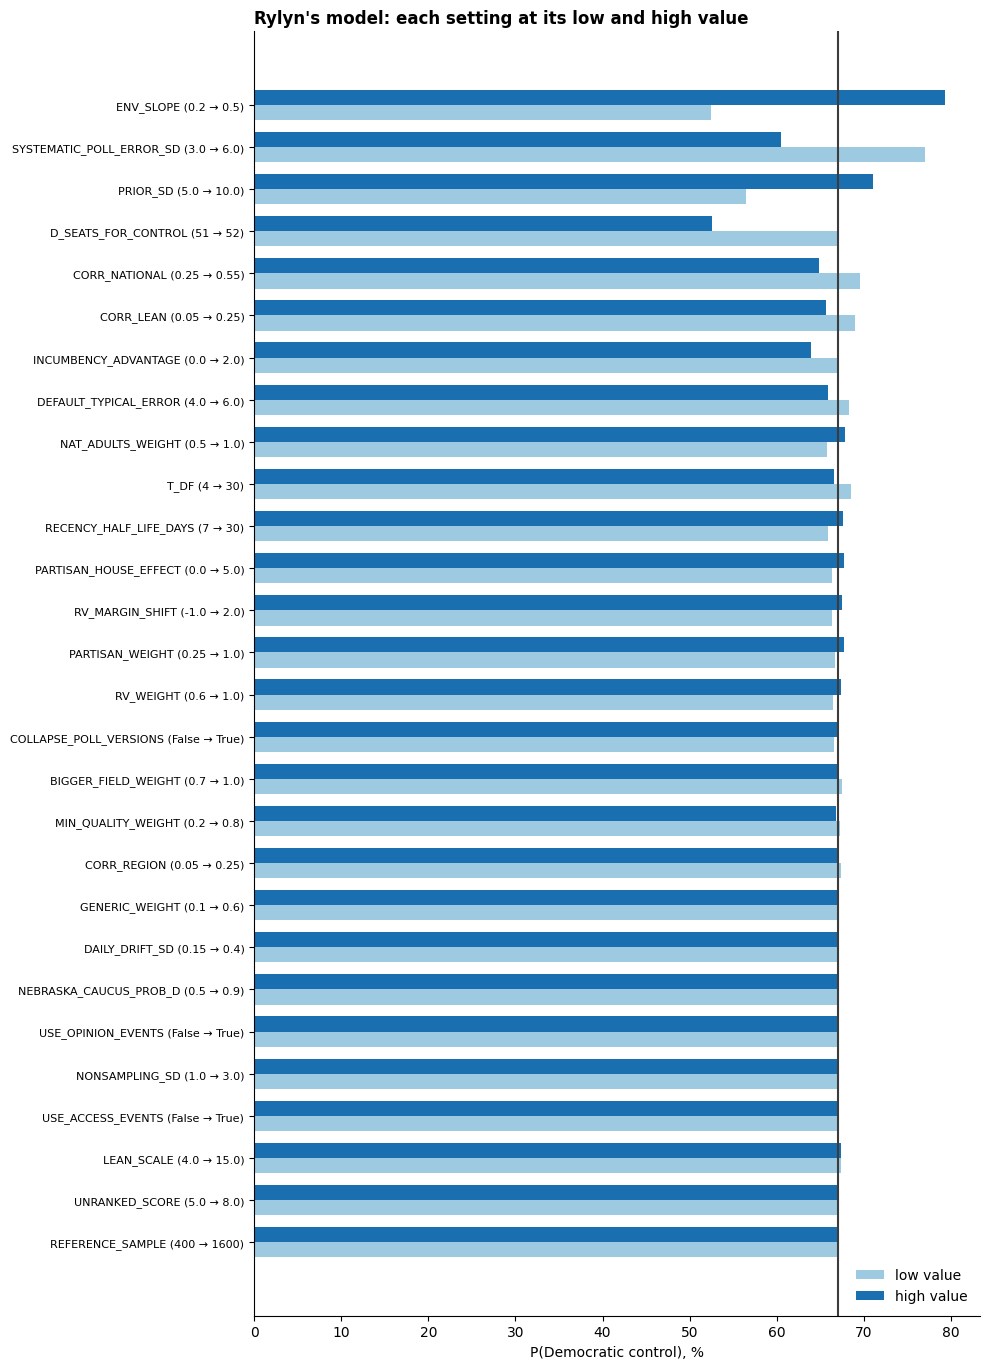

In [7]:
SWEEP = {
    "ENV_SLOPE": (0.20, 0.50),
    "PRIOR_SD": (5.0, 10.0),
    "SYSTEMATIC_POLL_ERROR_SD": (3.0, 6.0),
    "RV_MARGIN_SHIFT": (-1.0, 2.0),
    "INCUMBENCY_ADVANTAGE": (0.0, 2.0),
    "CORR_NATIONAL": (0.25, 0.55),
    "T_DF": (4, 30),
    "D_SEATS_FOR_CONTROL": (51, 52),
    "NEBRASKA_CAUCUS_PROB_D": (0.5, 0.9),
    "RECENCY_HALF_LIFE_DAYS": (7, 30),
    "DAILY_DRIFT_SD": (0.15, 0.40),
    "PARTISAN_HOUSE_EFFECT": (0.0, 5.0),
    "PARTISAN_WEIGHT": (0.25, 1.0),
    "RV_WEIGHT": (0.6, 1.0),
    "GENERIC_WEIGHT": (0.1, 0.6),
    "BIGGER_FIELD_WEIGHT": (0.7, 1.0),
    "COLLAPSE_POLL_VERSIONS": (False, True),
    "MIN_QUALITY_WEIGHT": (0.2, 0.8),
    "UNRANKED_SCORE": (5.0, 8.0),
    "DEFAULT_TYPICAL_ERROR": (4.0, 6.0),
    "NAT_ADULTS_WEIGHT": (0.5, 1.0),
    "CORR_REGION": (0.05, 0.25),
    "CORR_LEAN": (0.05, 0.25),
    "LEAN_SCALE": (4.0, 15.0),
    "NONSAMPLING_SD": (1.0, 3.0),
    "USE_OPINION_EVENTS": (False, True),
    "USE_ACCESS_EVENTS": (False, True),
    "REFERENCE_SAMPLE": (400, 1600),
}


def run_sweep(d, settings, today, n_sims, out_dir):
    def one(s):
        c = make_context(s, today, verbose=False)
        res = forecast(d, c, n_sims, with_base=False)
        seats = res.sim["d_seats"]
        row = {"P(D control)": (seats >= c.D_SEATS_FOR_CONTROL).mean(), "Mean D seats": seats.mean()}
        row.update({f"P(D) {st}": res.sim["p_dem"][st] for st in BATTLEGROUNDS})
        return row

    t0 = time.time()
    base = one(settings)
    print(f"Baseline: P(D control) {base['P(D control)']:.1%}, mean D seats {base['Mean D seats']:.2f}")
    rows = []
    for name, (lo, hi) in SWEEP.items():
        r_lo = one({**settings, name: lo})
        r_hi = one({**settings, name: hi})
        change = 100 * (r_hi["P(D control)"] - r_lo["P(D control)"])
        moves = {st: 100 * (r_hi[f"P(D) {st}"] - r_lo[f"P(D) {st}"]) for st in BATTLEGROUNDS}
        top_state = max(moves, key=lambda k: abs(moves[k]))
        row = {"setting": name, "current": settings[name], "low": lo, "high": hi,
               "P(D control) at low": r_lo["P(D control)"], "P(D control) at high": r_hi["P(D control)"],
               "change low->high (pts)": change,
               "raising it helps": "D" if change >= 0.5 else "R" if change <= -0.5 else "neither",   # under half a point = neither
               "mean D seats at low": r_lo["Mean D seats"], "mean D seats at high": r_hi["Mean D seats"],
               "battleground that moves most": top_state, "its change (pts)": moves[top_state]}
        for st in BATTLEGROUNDS:
            row[f"{st} low"] = r_lo[f"P(D) {st}"]
            row[f"{st} high"] = r_hi[f"P(D) {st}"]
        rows.append(row)
        print(f"  {name:26s} {str(lo):>6} -> {str(hi):<6}  P(D control) {r_lo['P(D control)']:.1%} -> "
              f"{r_hi['P(D control)']:.1%}  ({change:+.1f} pts)   most-moved race: {top_state} {moves[top_state]:+.0f}")
    table = pd.DataFrame(rows)
    table = table.reindex(table["change low->high (pts)"].abs().sort_values(ascending=False).index)
    table.insert(1, "baseline P(D control)", base["P(D control)"])
    table.to_csv(out_dir / "sensitivity.csv", index=False)
    print(f"\nSaved {out_dir / 'sensitivity.csv'} ({time.time() - t0:.0f} s)")
    return table


sweep = run_sweep(d, SETTINGS, c.TODAY, c.N_SIMS, TEST_DIR)
top = sweep.head(10)
fig, ax = plt.subplots(figsize=(10, 0.45 * len(sweep) + 1.2))
s = sweep.iloc[::-1]
y = np.arange(len(s))
ax.barh(y - 0.18, 100 * s["P(D control) at low"], height=0.36, color="#9ECAE1", label="low value")
ax.barh(y + 0.18, 100 * s["P(D control) at high"], height=0.36, color="#1A6FB0", label="high value")
ax.axvline(100 * sweep["baseline P(D control)"].iloc[0], color="#3C3C3C", lw=1.5)
ax.set_yticks(y, [f"{a} ({lo} → {hi})" for a, lo, hi in zip(s["setting"], s["low"], s["high"])], fontsize=8)
ax.set_xlabel("P(Democratic control), %")
ax.spines[["right", "top"]].set_visible(False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Rylyn's model: each setting at its low and high value", loc="left", fontweight="bold")
fig.tight_layout()
fig.savefig(TEST_DIR / "sensitivity_chart.png", dpi=200, bbox_inches="tight")
plt.show()
check("E", "most influential settings", "PASS",
      "; ".join(f"{x.setting}: {x['P(D control) at low']:.0%} -> {x['P(D control) at high']:.0%}" for _, x in top.head(3).iterrows()))

## F. Random seeds
Re-runs the forecast with 5 seeds. If P(control) moves by more than a point or two, raise `N_SIMS`.

In [8]:
rows = []
for sd in [SETTINGS["SEED"], 1, 7, 42, 99]:
    cs = make_context({**SETTINGS, "SEED": sd}, c.TODAY, verbose=False)
    rs = forecast(d, cs, cs.N_SIMS, with_base=False)
    rows.append({"seed": sd, "P(D control)": (rs.sim["d_seats"] >= cs.D_SEATS_FOR_CONTROL).mean(), "Mean D seats": rs.sim["d_seats"].mean()})
seeds = pd.DataFrame(rows)
display(seeds.round(4))
rg = seeds["P(D control)"].max() - seeds["P(D control)"].min()
check("F", "stable across random seeds", "PASS" if rg < 0.02 else "WARN", f"range {rg:.1%} over 5 seeds at {c.N_SIMS:,} simulations")
show_checks("F")

,seed,P(D control),Mean D seats
0,2026,0.6704,51.6909
1,1,0.6713,51.6520
2,7,0.6715,51.6320
3,42,0.6746,51.6820
4,99,0.6746,51.6908


,check,status,detail
0,stable across random seeds,PASS,"range 0.4% over 5 seeds at 10,000 simulations"


## G. Summary of every check
Saved to `Output/testing/checks.csv` (also read by `run_all.py`).

In [9]:
summary = pd.DataFrame(CHECKS)
summary.to_csv(TEST_DIR / "checks.csv", index=False)
counts = summary["status"].value_counts()
print(f"{counts.get('PASS', 0)} PASS | {counts.get('WARN', 0)} WARN | {counts.get('FAIL', 0)} FAIL")
try:
    display(summary.style.map(lambda v: COLORS.get(v, ""), subset=["status"]))
except (AttributeError, ImportError):
    display(summary)

16 PASS | 4 WARN | 0 FAIL


,section,check,status,detail
0,A,newest state poll,WARN,2026-10-15 (14 days before the forecast date)
1,A,newest approval poll,PASS,2026-10-15
2,A,polls dated after the forecast date,PASS,0 state polls are newer than 2026-10-29 and still count (the script has no as-of filter)
3,A,state polls with Dem% + Rep% > 100,WARN,New Mexico SurveyUSA 10/05 (54+47)
4,A,duplicate approval polls,WARN,2 rows: ['AlphaROC'] (counted twice in the approval average)
5,A,approval polls with no sample size,WARN,1 (get zero weight)
6,A,every race has a partisan lean,PASS,all 35
7,A,pollsters without a rank,PASS,0 polls use UNRANKED_SCORE = 6.5
8,A,events loaded,PASS,"4 opinion events, 5 of 11 access rows active, 1 map events"
9,B,probabilities between 0 and 1,PASS,state and national simulations
